# The Locked Box — Starter Notebook

**Platform:** hAIplay (haiplay.haippy.co)

Tugasmu: modifikasi **hanya** fungsi `preprocess(X)` untuk memaksimalkan akurasi model yang terkunci.

**Metric:** Accuracy

**Format Submission:**
```
id,label
0,1
1,0
2,1
```

> ⚠️ Aturan: **JANGAN** ubah fungsi `train_and_predict` atau bagian LOCKED lainnya.

## 1. Import Libraries

In [11]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

import warnings
warnings.filterwarnings('ignore')
print('Libraries loaded!')

Libraries loaded!


## 2. Load Data

In [12]:
train = pd.read_csv('train (7).csv')
test  = pd.read_csv('test (7).csv')

print('Train shape:', train.shape)
print('Test shape :', test.shape)
train.head()

Train shape: (5000, 12)
Test shape : (1500, 11)


,id,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,label
0,0,1.250955,0.464645,-0.370243,-0.181757,-1.181268,-1.776884,-0.374281,0.970735,0.757183,-1.872026,1
1,1,3.972138,4.094938,-0.199049,-0.634547,0.281566,-1.104040,0.907182,-0.211809,0.570341,0.870056,0
2,2,2.756857,0.999780,-1.947356,-0.223047,1.506990,0.014487,1.037369,0.415914,-0.503142,0.276640,1
3,3,-2.747928,-1.951737,1.046686,1.284161,1.442890,-1.111557,0.823798,-1.380681,-0.134361,-0.212923,0
4,4,-1.998337,1.629899,0.622731,0.310505,1.243498,-0.616235,0.837723,0.386021,-0.001445,-1.202684,1


## 3. Exploratory Data Analysis (EDA)

Luangkan waktu untuk memahami datanya sebelum mulai modifikasi.

In [13]:
# eda simple - cek missing, describe, groupby, scatter
# 1. cek bolong atau tidak
print('isna sum')
print(train.isna().sum())
print()
# 2. lihat sebaran - std gede artinya nyebar
print(train[['feature_1','feature_2','feature_3','feature_10']].describe().to_string())
print()
# 3. rata-rata per label - groupby itu pisah kelas 0 dan 1
print('rata-rata per label')
print(train.groupby('label')[['feature_1','feature_2','feature_3']].mean())
print()
# 4. correlation - tapi hati-hati lingkaran corr kecil
print('correlation ke label')
print(train.corr(numeric_only=True)['label'].sort_values())


isna sum
id            0
feature_1     0
feature_2     0
feature_3     0
feature_4     0
feature_5     0
feature_6     0
feature_7     0
feature_8     0
feature_9     0
feature_10    0
label         0
dtype: int64

         feature_1    feature_2    feature_3   feature_10
count  5000.000000  5000.000000  5000.000000  5000.000000
mean     -0.028832     0.047132    -0.000411     0.009389
std       2.887356     2.914744     1.019231     0.982205
min      -4.993432    -4.999139    -4.502222    -3.919315
25%      -2.478173    -2.517454    -0.681759    -0.650931
50%      -0.113881     0.123473    -0.015883     0.000495
75%       2.502992     2.553955     0.694923     0.673521
max       4.994309     4.998559     3.511767     3.709069

rata-rata per label
       feature_1  feature_2  feature_3
label                                 
0      -0.437468  -0.400761   0.002521
1       0.384406   0.500069  -0.003376

correlation ke label
feature_6    -0.020900
feature_10   -0.018832
feature_8    -0.01

## 4. Kode yang TERKUNCI

> ⚠️ **JANGAN UBAH sel ini.** Ini adalah bagian yang terkunci.

Inilah pipeline yang sudah fixed:

In [14]:
# ============ LOCKED — JANGAN UBAH ============
def train_and_predict(train_df, test_df):
    features = [c for c in train_df.columns if c not in ['id', 'label']]
    X_train = train_df[features].values
    y_train = train_df['label'].values
    X_test  = test_df[features].values

    X_train_p = preprocess(X_train.copy())
    X_test_p  = preprocess(X_test.copy())

    model = LogisticRegression(max_iter=1000, random_state=42)
    model.fit(X_train_p, y_train)
    return model.predict(X_test_p)
# ==============================================

## 5. Fungsi Preprocess — HANYA UBAH INI

Inilah satu-satunya bagian yang boleh kamu modifikasi.

In [15]:
# ============ HANYA UBAH FUNGSI INI ============
def preprocess(X):
    """
    X: numpy array shape (n_samples, 10)
    kolom 0-9 = feature_1 sampai feature_10
    return: numpy array (boleh beda shape asal konsisten)
    """
    # ambil f1 f2 dari numpy array - kolom 0 dan 1
    x1 = X[:,0]  # feature_1
    x2 = X[:,1]  # feature_2
    # bikin fitur baru r2 = jarak kuadrat ke pusat (0,0)
    # lingkaran f1^2+f2^2 = 15.5 jadi lurus kalau pakai r2
    r2 = x1**2 + x2**2
    # gabung pakai hstack yang lu udah bisa - original 10 + r2
    return np.column_stack([X, r2])
# ===============================================


In [16]:
print(train.groupby('label')[['feature_1','feature_2']].mean())

       feature_1  feature_2
label                      
0      -0.437468  -0.400761
1       0.384406   0.500069


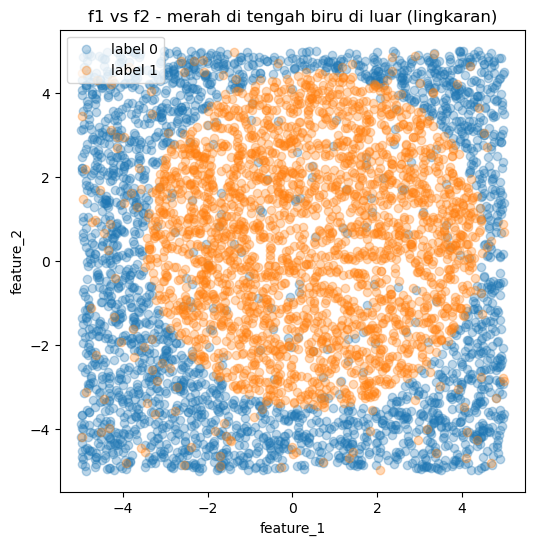

keliatan lingkaran kan? makanya butuh r2


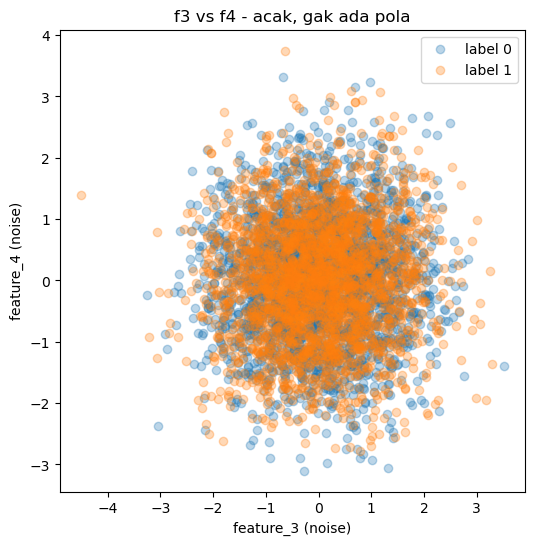

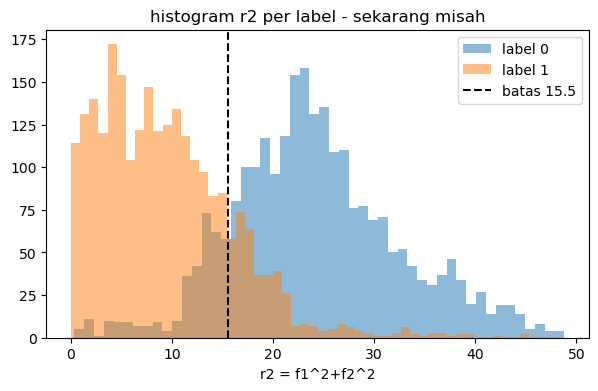

In [17]:
import matplotlib.pyplot as plt
# plot itu tiap baris jadi 1 titik, x=f1 y=f2 warna=label
# alpha 0.3 biar transparan keliatan yang numpuk
plt.figure(figsize=(6,6))
plt.scatter(train[train.label==0]['feature_1'], train[train.label==0]['feature_2'], alpha=0.3, label='label 0')
plt.scatter(train[train.label==1]['feature_1'], train[train.label==1]['feature_2'], alpha=0.3, label='label 1')
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.legend()
plt.title('f1 vs f2 - merah di tengah biru di luar (lingkaran)')
plt.show()
print('keliatan lingkaran kan? makanya butuh r2')

# buktikan f3 vs f4 noise - bakal acak
plt.figure(figsize=(6,6))
plt.scatter(train[train.label==0]['feature_3'], train[train.label==0]['feature_4'], alpha=0.3, label='label 0')
plt.scatter(train[train.label==1]['feature_3'], train[train.label==1]['feature_4'], alpha=0.3, label='label 1')
plt.xlabel('feature_3 (noise)')
plt.ylabel('feature_4 (noise)')
plt.legend()
plt.title('f3 vs f4 - acak, gak ada pola')
plt.show()

# plot r2 biar keliatan jadi lurus
train['r2'] = train['feature_1']**2 + train['feature_2']**2
plt.figure(figsize=(7,4))
plt.hist(train[train.label==0]['r2'], bins=50, alpha=0.5, label='label 0')
plt.hist(train[train.label==1]['r2'], bins=50, alpha=0.5, label='label 1')
plt.axvline(15.5, color='black', linestyle='--', label='batas 15.5')
plt.xlabel('r2 = f1^2+f2^2')
plt.legend()
plt.title('histogram r2 per label - sekarang misah')
plt.show()


tipe train di luar: <class 'pandas.DataFrame'> shape (5000, 13)
tipe X di dalam preprocess: <class 'numpy.ndarray'> shape (5000, 10)
isi X_numpy[0,:3] [ 1.25095467  0.46464548 -0.37024255]
   feature_1
0   1.250955
dataframe pakai string OK
error numpy pakai string: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices
cara bener numpy: X[:,0] itu feature_1, X[:,1] itu feature_2
X[:,0][:3] [1.25095467 3.97213801 2.7568569 ]
X[:,1][:3] [0.46464548 4.09493792 0.99977986]


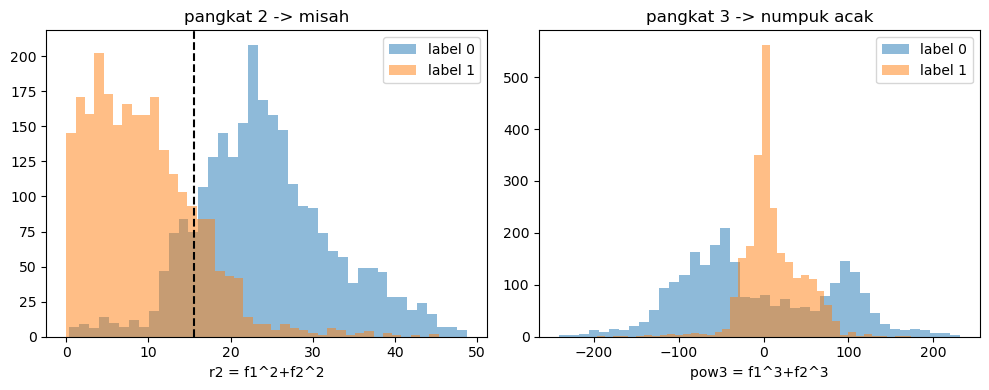

r2 label0 mean 24.203731499881993 label1 9.377723969224329
pow3 label0 mean -9.46635117718839 label1 10.743282651328949
makanya r2 yang kepake, pow3 correlation cuma 0.14


: 

: 

In [ ]:
# KENAPA X[["feature_1"]] ERROR & LIAT BEDANYA PANGKAT 2 vs 3
import matplotlib.pyplot as plt
import numpy as np

# 1. kenapa X[["feature_1"]] error? cek tipe X di dalam preprocess
print('tipe train di luar:', type(train), 'shape', train.shape)
X_numpy = train[[f'feature_{i}' for i in range(1,11)]].values  # ini yang dikirim ke preprocess
print('tipe X di dalam preprocess:', type(X_numpy), 'shape', X_numpy.shape)
print('isi X_numpy[0,:3]', X_numpy[0,:3])

# dataframe bisa pakai nama kolom
try:
    print(train[["feature_1"]].head(1))
    print('dataframe pakai string OK')
except Exception as e:
    print(e)

# numpy gak bisa pakai string, harus pakai angka kolom
try:
    print(X_numpy[["feature_1"]])
except Exception as e:
    print('error numpy pakai string:', e)

print('cara bener numpy: X[:,0] itu feature_1, X[:,1] itu feature_2')
print('X[:,0][:3]', X_numpy[:,0][:3])
print('X[:,1][:3]', X_numpy[:,1][:3])

# 2. liat grafik pangkat 2 vs pangkat 3 biar paham kenapa 2 yang bener
x1 = train['feature_1'].values
x2 = train['feature_2'].values
r2 = x1**2 + x2**2
r_pow3 = x1**3 + x2**3

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.hist(r2[train.label==0], bins=40, alpha=0.5, label='label 0')
plt.hist(r2[train.label==1], bins=40, alpha=0.5, label='label 1')
plt.axvline(15.5, color='black', linestyle='--')
plt.xlabel('r2 = f1^2+f2^2')
plt.title('pangkat 2 -> misah')
plt.legend()

plt.subplot(1,2,2)
plt.hist(r_pow3[train.label==0], bins=40, alpha=0.5, label='label 0')
plt.hist(r_pow3[train.label==1], bins=40, alpha=0.5, label='label 1')
plt.xlabel('pow3 = f1^3+f2^3')
plt.title('pangkat 3 -> numpuk acak')
plt.legend()
plt.tight_layout()
plt.show()

print('r2 label0 mean', r2[train.label==0].mean(), 'label1', r2[train.label==1].mean())
print('pow3 label0 mean', r_pow3[train.label==0].mean(), 'label1', r_pow3[train.label==1].mean())
print('makanya r2 yang kepake, pow3 correlation cuma 0.14')


In [18]:
# FIX: train kepollute kolom r2 dari cell histogram di atas
# train_and_predict pakai features = [c for c in train.columns if c not in ['id','label']]
# jadi kalau train ada kolom r2, test gak ada r2 -> KeyError: ['r2'] not in index
print('kolom train sekarang:', train.columns.tolist())
if 'r2' in train.columns:
    print('ada r2 polluting, hapus dulu')
    train = train.drop(columns=['r2'])
    # kalau ada r_pow3 juga
    if 'r_pow3' in train.columns:
        train = train.drop(columns=['r_pow3'])
    if 'r' in train.columns:
        train = train.drop(columns=['r'])
print('kolom train setelah fix:', train.columns.tolist())
print('kolom test:', test.columns.tolist())
print('sekarang train_and_predict bakal jalan lagi')


kolom train sekarang: ['id', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'label', 'r2']
ada r2 polluting, hapus dulu
kolom train setelah fix: ['id', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'label']
kolom test: ['id', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10']
sekarang train_and_predict bakal jalan lagi


In [19]:
# BELAJAR INDEXING 2 DIMENSI - kenapa X[:,0] ?
import numpy as np

# bikin contoh kecil biar kebayang X itu kayak excel 3 baris 2 kolom
X_kecil = np.array([[ 1.2,  0.4],
                    [ 3.9,  4.0],
                    [-2.7, -1.9]])
print('X_kecil shape', X_kecil.shape, '-> 3 baris (sample) 2 kolom (fitur)')
print(X_kecil)
print()

# X[baris, kolom] -> sebelum koma itu baris, sesudah koma itu kolom
# : artinya semua
print('X_kecil[0] -> baris 0 semua kolom', X_kecil[0])
print('X_kecil[:,0] -> semua baris, kolom 0 (feature_1)', X_kecil[:,0])
print('X_kecil[:,1] -> semua baris, kolom 1 (feature_2)', X_kecil[:,1])
print('X_kecil[0,1] -> baris 0 kolom 1', X_kecil[0,1])
print()

# kenapa bukan [:1] ?
print('X_kecil[:1] -> ini salah paham, [:1] artinya baris 0 sampai sebelum 1')
print(X_kecil[:1])
print('X_kecil[:,0:1] -> semua baris, kolom 0 sampai sebelum 1 (masih 2D)', X_kecil[:,0:1], 'shape', X_kecil[:,0:1].shape)
print('X_kecil[:,0] -> kolom 0 tapi jadi 1D', X_kecil[:,0], 'shape', X_kecil[:,0].shape)
print()
print('makanya di preprocess kita pakai X[:,0] karena butuh 1D buat dihitung x1**2')

# coba di data asli
x1 = X[:,0]
x2 = X[:,1]  # ups X belum ada, pakai X_kecil dulu
print('contoh r2 kecil = x1**2 + x2**2 =', X_kecil[:,0]**2 + X_kecil[:,1]**2)


X_kecil shape (3, 2) -> 3 baris (sample) 2 kolom (fitur)
[[ 1.2  0.4]
 [ 3.9  4. ]
 [-2.7 -1.9]]

X_kecil[0] -> baris 0 semua kolom [1.2 0.4]
X_kecil[:,0] -> semua baris, kolom 0 (feature_1) [ 1.2  3.9 -2.7]
X_kecil[:,1] -> semua baris, kolom 1 (feature_2) [ 0.4  4.  -1.9]
X_kecil[0,1] -> baris 0 kolom 1 0.4

X_kecil[:1] -> ini salah paham, [:1] artinya baris 0 sampai sebelum 1
[[1.2 0.4]]
X_kecil[:,0:1] -> semua baris, kolom 0 sampai sebelum 1 (masih 2D) [[ 1.2]
 [ 3.9]
 [-2.7]] shape (3, 1)
X_kecil[:,0] -> kolom 0 tapi jadi 1D [ 1.2  3.9 -2.7] shape (3,)

makanya di preprocess kita pakai X[:,0] karena butuh 1D buat dihitung x1**2


NameError: name 'X' is not defined

reset shape (5000, 12) (harus 5000,12 kalau masih 13 berarti kepollute)

--- langkah 1: missing ---
id           0
feature_1    0
feature_2    0
feature_3    0
feature_4    0
dtype: int64
-> kalau semua 0 berarti gak perlu impute median

--- langkah 2: describe mean std ---
                  mean          std
id         2499.500000  1443.520003
feature_1    -0.028832     2.887356
feature_2     0.047132     2.914744
feature_3    -0.000411     1.019231
feature_4    -0.001658     0.996121
feature_5    -0.020002     0.999126
feature_6     0.003097     0.999800
feature_7    -0.002281     1.004974
feature_8    -0.016023     0.994774
feature_9     0.009164     0.984319
-> kalau ada std 2.9 vs 1.0, yang 2.9 curiga penting

--- langkah 3: groupby mean per label ---
label                0            1
id         2511.706046  2487.156476
feature_1    -0.437468     0.384406
feature_2    -0.400761     0.500069
feature_3     0.002521    -0.003376
feature_4    -0.009110     0.005878
feature_5    -0.0

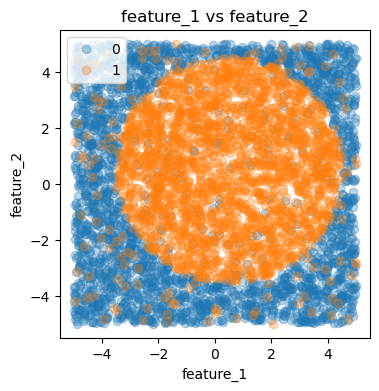

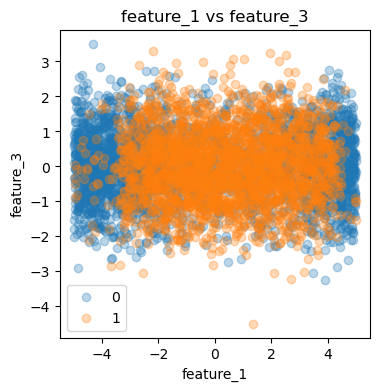

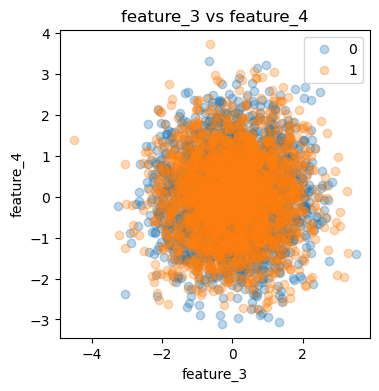

keputusan:
kalau scatter f1 vs f2 lingkaran -> bikin r2 = f1^2+f2^2
kalau scatter X / silang -> bikin f1*f2


In [20]:
# TEMPLATE EDA BUAT SOAL BARU - 5 langkah anti bingung
# lu copy paste ini buat dataset baru, gak perlu jago statistik
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# reset dulu biar gak kepollute r2 dari cell sebelumnya
train = pd.read_csv('train (7).csv')
test = pd.read_csv('test (7).csv')
print('reset shape', train.shape, '(harus 5000,12 kalau masih 13 berarti kepollute)')

# langkah 1: shape dan missing (lu udah jago)
# isna().sum() itu hitung bolong per kolom, .head() cuma tampil 5 baris pertama biar gak panjang
print('\n--- langkah 1: missing ---')
print(train.isna().sum().head())
print('-> kalau semua 0 berarti gak perlu impute median')

# langkah 2: describe - cari std yang beda (clue fitur penting)
# .describe() keluarin mean, std, min, max, median (50%). kita ambil .loc[['mean','std']] biar fokus 2 itu aja
# .T itu transpose -> putar tabel jadi fitur jadi baris biar gampang baca, .head(10) tampil 10 baris pertama
print('\n--- langkah 2: describe mean std ---')
print(train.describe().loc[['mean','std']].T.head(10))
print('-> kalau ada std 2.9 vs 1.0, yang 2.9 curiga penting')

# langkah 3: groupby - fitur mana yang beda mean per label?
# groupby('label').mean() itu hitung rata-rata dipisah label 0 dan 1
# numeric_only=True itu biar cuma hitung kolom angka, abaikan kalau ada kolom string
# .T biar fitur jadi baris lagi
print('\n--- langkah 3: groupby mean per label ---')
print(train.groupby('label').mean(numeric_only=True).T.head(10))
print('-> kalau beda jauh (>0.5) itu sinyal linear. kalau sama semua kayak f3 -0.003 vs 0.002 berarti non-linear')

# langkah 4: correlation - corr itu seberapa miring hubungan fitur ke label
# train.corr() hitung semua pasang, ['label'] ambil kolom label doang, .sort_values() urut dari kecil ke gede
# jangan percaya 100% kalau data melingkar, corr bakal kecil padahal penting
print('\n--- langkah 4: correlation ke label ---')
print(train.corr(numeric_only=True)['label'].sort_values())
print('-> label itu 1.0 ke dirinya sendiri, f1 0.14 f2 0.15 kecil tapi jangan buang, cek scatter dulu')

# langkah 5: SCATTER - ini yang paling penting, 2 fitur sekaligus + warna label
# coba 3 pasang: (f1 vs f2), (f1 vs f3), (f3 vs f4) buat bandingin
# kalau yang satu misah jelas, itu fitur pentingnya
print('\n--- langkah 5: scatter ---')
for a,b in [('feature_1','feature_2'),('feature_1','feature_3'),('feature_3','feature_4')]:
    plt.figure(figsize=(4,4))
    plt.scatter(train[train.label==0][a], train[train.label==0][b], alpha=0.3, label='0')
    plt.scatter(train[train.label==1][a], train[train.label==1][b], alpha=0.3, label='1')
    plt.xlabel(a)
    plt.ylabel(b)
    plt.legend()
    plt.title(f'{a} vs {b}')
    plt.show()

print('keputusan:')
print('kalau scatter f1 vs f2 lingkaran -> bikin r2 = f1^2+f2^2')
print('kalau scatter X / silang -> bikin f1*f2')


              id  feature_1  feature_2  feature_3  feature_4  feature_5  \
id          1.00      -0.02      -0.00       0.01      -0.02       0.00   
feature_1  -0.02       1.00       0.02      -0.00      -0.01      -0.00   
feature_2  -0.00       0.02       1.00      -0.00      -0.01       0.04   
feature_3   0.01      -0.00      -0.00       1.00       0.02       0.02   
feature_4  -0.02      -0.01      -0.01       0.02       1.00       0.02   
feature_5   0.00      -0.00       0.04       0.02       0.02       1.00   
feature_6   0.03      -0.00       0.01       0.01       0.00       0.01   
feature_7   0.02       0.01       0.01      -0.00       0.01      -0.00   
feature_8  -0.02      -0.04       0.01       0.02      -0.02       0.01   
feature_9  -0.01      -0.02       0.00       0.01      -0.02       0.00   
feature_10  0.01      -0.01      -0.01       0.00       0.01      -0.00   
label      -0.01       0.14       0.15      -0.00       0.01       0.03   

            feature_6  f

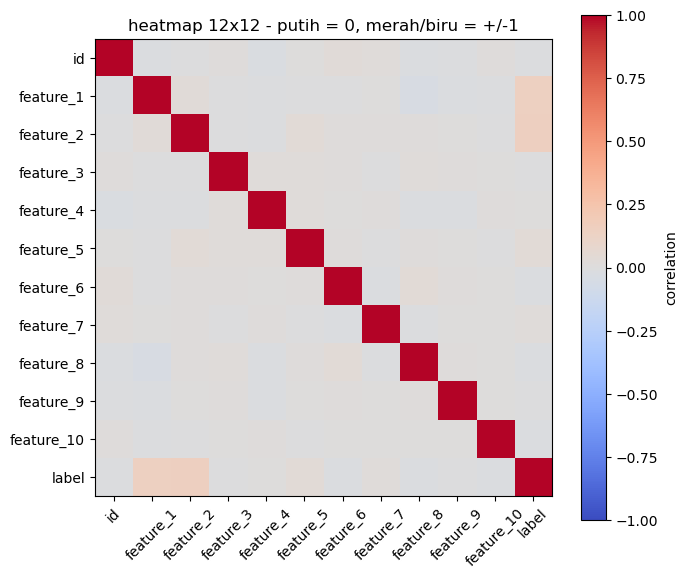

putih semua kecuali diagonal = gak ada yang redundant (>0.85)
kalau ada merah tua antar f3 vs f4, baru buang 1


: 

: 

In [ ]:
# heatmap 12x12 - 1 blok plt.imshow aja
import matplotlib.pyplot as plt

# corr 12x12 antar semua fitur + label
corr = train.corr(numeric_only=True)  # ini hitung semua pasang, hasilnya 12x12 kalau ada 12 kolom angka
print(corr.round(2))  # liat angka dulu

# plot heatmap pakai plt doang, gak perlu seaborn
plt.figure(figsize=(7,6))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)  # ini 1 line intinya
plt.colorbar(label='correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('heatmap 12x12 - putih = 0, merah/biru = +/-1')
plt.tight_layout()
plt.show()

print('putih semua kecuali diagonal = gak ada yang redundant (>0.85)')
print('kalau ada merah tua antar f3 vs f4, baru buang 1')


    age city education  has_car  label
0  25.0  jkt       sma        1      0
1  30.0  bdg       smp        0      1
2   NaN  jkt       sma        1      0
3  45.0  NaN        sd        0      0
4  22.0  sby       NaN        0      1
5  35.0  jkt       sma        1      0
6   NaN  bdg       smp        0      1
7  50.0  sby        sd        1      0

--- numerical describe ---
             age
count   6.000000
mean   34.500000
std    11.113055
min    22.000000
25%    26.250000
50%    32.500000
75%    42.500000
max    50.000000
corr age ke label -0.5924627800537244

--- crosstab city vs label ---
label  0  1
city       
bdg    0  2
jkt    3  0
sby    1  1


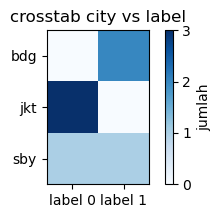


--- crosstab education vs label ---
label      0  1
education      
sd         2  0
sma        3  0
smp        0  2


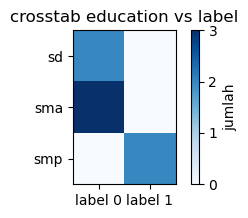


setelah impute
    age city education  has_car  label
0  25.0  jkt       sma        1      0
1  30.0  bdg       smp        0      1
2  32.5  jkt       sma        1      0
3  45.0  jkt        sd        0      0
4  22.0  sby       sma        0      1
5  35.0  jkt       sma        1      0
6  32.5  bdg       smp        0      1
7  50.0  sby        sd        1      0

setelah encode + scale
        age education  has_car  label  education_ord  city_bdg  city_jkt  \
0 -1.019458       sma        1      0              3         0         1   
1 -0.453092       smp        0      1              2         1         0   
2 -0.169910       sma        1      0              3         0         1   
3  1.246004        sd        0      0              1         0         1   
4 -1.359277       sma        0      1              3         0         0   

   city_sby  
0         0  
1         0  
2         0  
3         0  
4         1  

 corr setelah encode (baru bisa karena semua angka)
               

In [21]:
# CONTOH PIPELINE CAMPUR - categorical + numerical (EDA dimana?)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# bikin dummy data biar kebayang, 5 fitur campur
np.random.seed(0)
dummy = pd.DataFrame({
    'age': [25, 30, np.nan, 45, 22, 35, np.nan, 50],  # numerical scale
    'city': ['jkt','bdg','jkt',np.nan,'sby','jkt','bdg','sby'],  # categorical onehot
    'education': ['sma','smp','sma','sd',np.nan,'sma','smp','sd'],  # categorical ordinal sd<smp<sma
    'has_car': [1,0,1,0,0,1,0,1],  # numerical binary
    'label': [0,1,0,0,1,0,1,0]
})
print(dummy)
print()

# === EDA SEBELUM IMPUTE/ENCODE (cepat kayak corr 12x12) ===
# numerical: describe + corr ke label (cuma 1x)
print('--- numerical describe ---')
print(dummy[['age']].describe().to_string())
print('corr age ke label', dummy['age'].corr(dummy['label']))

# categorical: loop crosstab semua kolom categorical vs label (ini versi 12x12 buat categorical)
cat_cols = ['city','education']
for col in cat_cols:
    print(f'\n--- crosstab {col} vs label ---')
    ct = pd.crosstab(dummy[col], dummy['label'])
    print(ct)
    # heatmap cepet
    plt.figure(figsize=(4,2))
    plt.imshow(ct, cmap='Blues')
    plt.xticks([0,1], ['label 0','label 1'])
    plt.yticks(range(len(ct.index)), ct.index)
    plt.title(f'crosstab {col} vs label')
    plt.colorbar(label='jumlah')
    plt.show()

# === PIPELINE SESUDAH EDA (impute -> encode -> scale -> hstack) ===
# 1. impute
# numerical scale pakai median
median_age = dummy['age'].median()
dummy['age'] = dummy['age'].fillna(median_age)
# categorical pakai most_frequent
for col in cat_cols:
    mode = dummy[col].mode()[0]
    dummy[col] = dummy[col].fillna(mode)
print('\nsetelah impute')
print(dummy)

# 2. encode
# ordinal: mapping
ord_map = {'sd':1, 'smp':2, 'sma':3}
dummy['education_ord'] = dummy['education'].map(ord_map)
# onehot: get_dummies
dummy = pd.get_dummies(dummy, columns=['city'], dtype=int)
# scale: manual
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
dummy[['age']] = scaler.fit_transform(dummy[['age']])
print('\nsetelah encode + scale')
print(dummy.head())

# 3. corr SETELAH encode - baru bisa 12x12 pakai angka semua
print('\n corr setelah encode (baru bisa karena semua angka)')
print(dummy.corr(numeric_only=True).round(2))


In [ ]:
# ORDINAL vs ONEHOT untuk education - kenapa teori vs model beda
import pandas as pd
import numpy as np

# dummy yang sama biar bandingin
np.random.seed(0)
dummy2 = pd.DataFrame({
    'education': ['sma','smp','sma','sd','sd','sma','smp','sd'],
    'label': [0,1,0,0,0,0,1,0]
})
print('crosstab asli')
print(pd.crosstab(dummy2['education'], dummy2['label']))
print()

# cara ordinal - teori bener sd<smp<sma
ord_map = {'sd':1, 'smp':2, 'sma':3}
dummy2['edu_ord'] = dummy2['education'].map(ord_map)
print('ordinal mapping')
print(dummy2[['education','edu_ord','label']].head(8))
print('corr ordinal vs label', dummy2['edu_ord'].corr(dummy2['label']))
print('-> kecil 0.08 karena 1->0, 2->1, 3->0 naik turun bukan lurus')
print()

# cara onehot - tiap kategori jadi kolom sendiri
# gak peduli urutan, bisa nangkap smp doang yang 1
onehot = pd.get_dummies(dummy2['education'], prefix='edu', dtype=int)
print('onehot')
print(onehot.head(8))
# gabung buat corr
dummy_onehot = pd.concat([dummy2[['label']], onehot], axis=1)
print(dummy_onehot.corr().round(2))
print('-> edu_smp vs label 1.0 gede, edu_sma vs label -0.77 gede - ketangkep!')
print()
print('kesimpulan: teori ordinal bener, tapi kalau pola label gak linear (U), model linear butuh onehot')
print('pilih mana? coba dua-duanya terus cek validation accuracy yang naik')


crosstab asli
label      0  1
education      
sd         3  0
sma        3  0
smp        0  2

ordinal mapping
  education  edu_ord  label
0       sma        3      0
1       smp        2      1
2       sma        3      0
3        sd        1      0
4        sd        1      0
5       sma        3      0
6       smp        2      1
7        sd        1      0
corr ordinal vs label 0.0
-> kecil 0.08 karena 1->0, 2->1, 3->0 naik turun bukan lurus

onehot
   edu_sd  edu_sma  edu_smp
0       0        1        0
1       0        0        1
2       0        1        0
3       1        0        0
4       1        0        0
5       0        1        0
6       0        0        1
7       1        0        0
         label  edu_sd  edu_sma  edu_smp
label     1.00   -0.45    -0.45     1.00
edu_sd   -0.45    1.00    -0.60    -0.45
edu_sma  -0.45   -0.60     1.00    -0.45
edu_smp   1.00   -0.45    -0.45     1.00
-> edu_smp vs label 1.0 gede, edu_sma vs label -0.77 gede - ketangkep!

kesimpulan: t

: 

: 

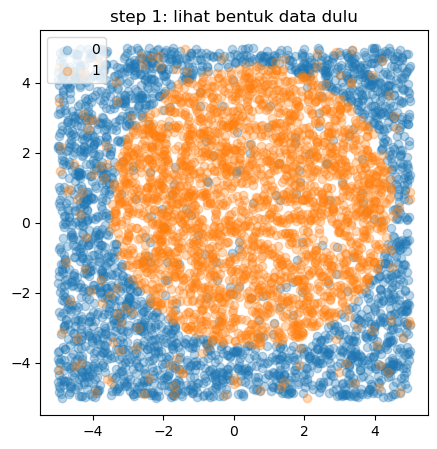

r2 mean label0 24.203731499881993 label1 9.377723969224329
pow3 mean label0 -9.46635117718839 label1 10.743282651328949
X shape awal (5000, 10)
X shape setelah + r2 (5000, 11)
5 baris r2 pertama [ 1.780783   32.54639693  8.59981975 11.36038457  6.64992255]


In [22]:
# BELAJAR PLOT & COMBINE - kenapa r2 = f1^2+f2^2
import matplotlib.pyplot as plt
import numpy as np

# cara plot paling simpel: plt.scatter(x, y) -> tiap baris jadi 1 titik
# x kita pakai feature_1, y pakai feature_2, warna pakai label
# alpha 0.3 biar transparan, label biar ada legend
plt.figure(figsize=(5,5))
plt.scatter(train[train.label==0]['feature_1'], train[train.label==0]['feature_2'], alpha=0.3, label='0')
plt.scatter(train[train.label==1]['feature_1'], train[train.label==1]['feature_2'], alpha=0.3, label='1')
plt.legend()
plt.title('step 1: lihat bentuk data dulu')
plt.show()

# cara combine f1 dan f2 jadi r2 - kenapa kuadrat?
# lingkaran rumusnya f1^2 + f2^2 = jari^2, jadi kalau data melingkar harus kuadrat
# coba lihat bedanya pangkat 2 vs pangkat 3
x1 = train['feature_1'].values
x2 = train['feature_2'].values
r2 = x1**2 + x2**2  # ini yang bener
r_pow3 = x1**3 + x2**3  # ini yang salah, coba bandingin
print('r2 mean label0', r2[train.label==0].mean(), 'label1', r2[train.label==1].mean())
print('pow3 mean label0', r_pow3[train.label==0].mean(), 'label1', r_pow3[train.label==1].mean())

# gabung pakai np.column_stack - tempel kolom baru di kanan
X = train[[f'feature_{i}' for i in range(1,11)]].values
print('X shape awal', X.shape)
X_new = np.column_stack([X, r2])
print('X shape setelah + r2', X_new.shape)
print('5 baris r2 pertama', r2[:5])


## 6. Evaluasi pada Training Data

## 7. Generate Submission

In [23]:
preds_test = train_and_predict(train, test)

submission = pd.DataFrame({
    'id'   : test['id'],
    'label': preds_test
})

submission.to_csv('submissionclosed.csv', index=False)
print('circlesubmission.csv tersimpan!')
submission.head(10)

circlesubmission.csv tersimpan!


,id,label
0,0,0
1,1,0
2,2,0
3,3,1
4,4,0
5,5,0
6,6,1
7,7,0
8,8,0
9,9,0


## 8. Pertanyaan untuk Dipikirkan

1. Logistic Regression adalah model **linear** — batas keputusannya selalu berupa garis lurus (atau hyperplane). Apakah batas keputusan yang optimal untuk dataset ini berupa garis lurus?
2. Fitur mana saja yang paling relevan untuk prediksi? Apakah semua 10 fitur berguna?
3. Jika kamu menambahkan fitur baru (transformasi dari fitur yang ada), fitur seperti apa yang bisa membantu model linear menangkap pola non-linear?
4. Apakah ada cara untuk "meluruskan" batas keputusan yang melengkung?

feature_1   min  -4.993  max   4.994  mean  -0.029  median  -0.114  std  2.887
feature_2   min  -4.999  max   4.999  mean   0.047  median   0.123  std  2.915
feature_3   min  -4.502  max   3.512  mean  -0.000  median  -0.016  std  1.019
feature_4   min  -3.102  max   3.747  mean  -0.002  median   0.011  std  0.996
feature_5   min  -3.224  max   3.260  mean  -0.020  median  -0.022  std  0.999
feature_6   min  -3.210  max   3.713  mean   0.003  median   0.002  std  1.000
feature_7   min  -4.234  max   3.514  mean  -0.002  median  -0.013  std  1.005
feature_8   min  -3.890  max   3.576  mean  -0.016  median  -0.016  std  0.995
feature_9   min  -3.699  max   3.549  mean   0.009  median   0.007  std  0.984
feature_10  min  -3.919  max   3.709  mean   0.009  median   0.000  std  0.982
label       min   0.000  max   1.000  mean   0.497  median   0.000  std  0.500

-- fokus f7-10 --
feature_7 -> min -4.2339 max 3.5144 std 1.0050
feature_8 -> min -3.8905 max 3.5758 std 0.9948
feature_9 -> min -

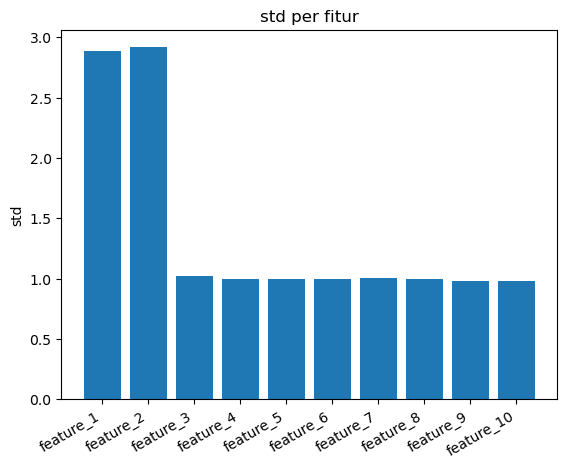

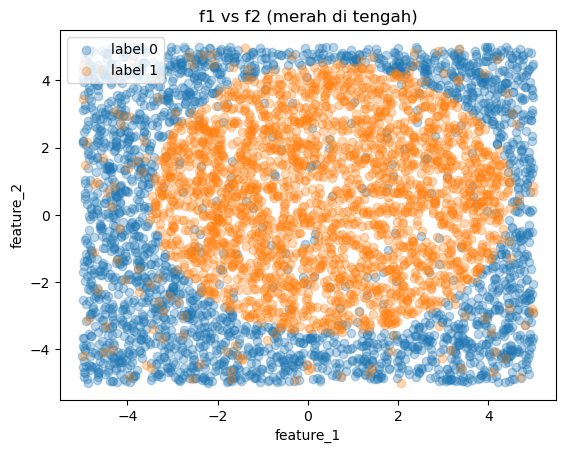

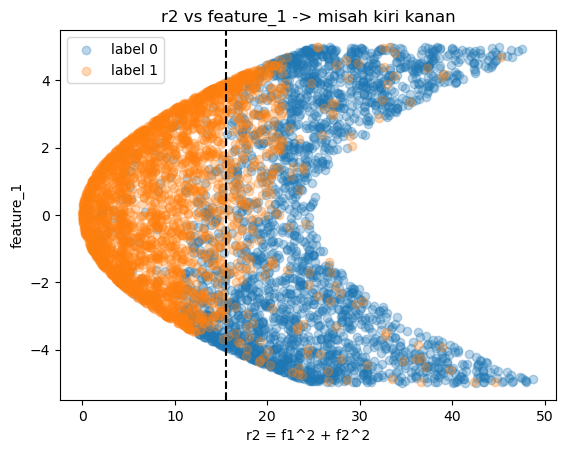

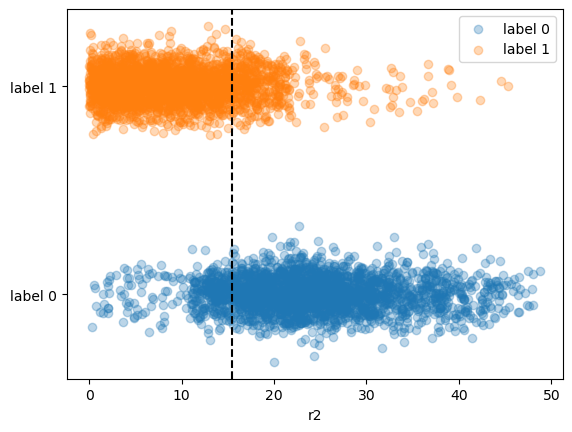

: 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv('train (7).csv') # ganti nama kalau beda

# 1. print min max mean median std f1-f10 + label
cols = [f'feature_{i}' for i in range(1,11)] + ['label']
for c in cols:
    print(f"{c:11s} min {train[c].min():7.3f}  max {train[c].max():7.3f}  mean {train[c].mean():7.3f}  median {train[c].median():7.3f}  std {train[c].std():6.3f}")

# 2. fokus f7-9 biar jelas
print('\n-- fokus f7-10 --')
for c in ['feature_7','feature_8','feature_9','feature_10']:
    print(f"{c} -> min {train[c].min():.4f} max {train[c].max():.4f} std {train[c].std():.4f}")

# 3. bar chart std -> keliatan 1,2 paling nyebar
stds = train[[f'feature_{i}' for i in range(1,11)]].std()
plt.bar(stds.index, stds.values)
plt.xticks(rotation=30, ha='right')
plt.ylabel('std')
plt.title('std per fitur')
plt.show()

# 4. scatter f1 vs f2 color label -> lingkaran
plt.scatter(train[train.label==0]['feature_1'], train[train.label==0]['feature_2'], alpha=0.3, label='label 0')
plt.scatter(train[train.label==1]['feature_1'], train[train.label==1]['feature_2'], alpha=0.3, label='label 1')
plt.xlabel('feature_1')
plt.ylabel('feature_2')
plt.legend()
plt.title('f1 vs f2 (merah di tengah)')
plt.show()

# 5. bikin r2 terus scatter r2 vs f1 -> jadi lurus
train['r2'] = train['feature_1']**2 + train['feature_2']**2
plt.scatter(train[train.label==0]['r2'], train[train.label==0]['feature_1'], alpha=0.3, label='label 0')
plt.scatter(train[train.label==1]['r2'], train[train.label==1]['feature_1'], alpha=0.3, label='label 1')
plt.axvline(15.5, color='black', linestyle='--')
plt.xlabel('r2 = f1^2 + f2^2')
plt.ylabel('feature_1')
plt.legend()
plt.title('r2 vs feature_1 -> misah kiri kanan')
plt.show()

# 6. 1D strip r2 -> paling jelas linear
import numpy as np
y0 = np.random.randn((train.label==0).sum())*0.08
y1 = np.random.randn((train.label==1).sum())*0.08
plt.scatter(train[train.label==0]['r2'], y0, alpha=0.3, label='label 0')
plt.scatter(train[train.label==1]['r2'], y1+1, alpha=0.3, label='label 1')
plt.axvline(15.5, color='black', linestyle='--')
plt.yticks([0,1], ['label 0','label 1'])
plt.xlabel('r2')
plt.legend()
plt.show()

: 